In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:\Retail_Sales_Analysis\Retail_Sales_Cleaned.csv")

df.head()

,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Discount,Sales,Profit,Year,Month,Sales Category,Profit Margin
0,ORD10181,01-01-2025,Deepak Patil,East,Bhubaneswar,Furniture,Chairs,Executive Chair,6,0%,"14,565.72","2,664.67",2025,Jan,High,18.29%
1,ORD10070,01-01-2025,Manish Chavan,South,Hyderabad,Technology,Phones,Business Phone,5,0%,"1,53,118.95","29,734.03",2025,Jan,High,19.42%
2,ORD10170,03-01-2025,Akash Verma,East,Bhubaneswar,Office Supplies,Paper,A4 Paper Pack,4,10%,"14,739.16","2,479.43",2025,Jan,High,16.82%
3,ORD10373,04-01-2025,Rahul Shah,West,Kolhapur,Technology,Printers,Inkjet Printer,2,20%,"87,786.90","5,093.42",2025,Jan,High,5.80%
4,ORD10135,04-01-2025,Meena Iyer,North,Lucknow,Furniture,Bookcases,Office Bookcase,1,0%,"8,985.34","2,072.17",2025,Jan,High,23.06%


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.info()

Dataset Shape: (500, 16)

Column Names:
['Order ID', 'Order Date', 'Customer Name', 'Region', 'City', 'Category', 'Sub-Category', 'Product Name', 'Quantity', 'Discount', 'Sales', 'Profit', 'Year', 'Month', 'Sales Category', 'Profit Margin']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Order ID        500 non-null    object
 1   Order Date      500 non-null    object
 2   Customer Name   500 non-null    object
 3   Region          500 non-null    object
 4   City            500 non-null    object
 5   Category        500 non-null    object
 6   Sub-Category    500 non-null    object
 7   Product Name    500 non-null    object
 8   Quantity        500 non-null    int64 
 9   Discount        500 non-null    object
 10  Sales           500 non-null    object
 11  Profit          500 non-null    object
 12  Year            500 non-null    i

In [5]:
# Convert numeric columns to numeric data types
numeric_cols = [
    "Quantity",
    "Discount",
    "Sales",
    "Profit",
    "Year",
    "Profit Margin"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)

Quantity           int64
Discount         float64
Sales            float64
Profit           float64
Year               int64
Profit Margin    float64
dtype: object


In [6]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())

Total Sales: 7760.44
Total Profit: 58129.3
Total Quantity: 2013


In [7]:
print("Missing Sales:", df["Sales"].isna().sum())
print("Missing Profit:", df["Profit"].isna().sum())
print("Missing Quantity:", df["Quantity"].isna().sum())

Missing Sales: 487
Missing Profit: 369
Missing Quantity: 0


In [9]:
df = pd.read_csv("C:\Retail_Sales_Analysis\Retail_Sales_Cleaned.csv")

print("Sales examples:")
print(df["Sales"].head(15).tolist())

print("\nProfit examples:")
print(df["Profit"].head(15).tolist())

print("\nOriginal data types:")
print(df[["Sales", "Profit", "Quantity"]].dtypes)

Sales examples:
['14,565.72', '1,53,118.95', '14,739.16', '87,786.90', '8,985.34', '51,151.64', '48,513.40', '96,888.84', '6,241.88', '1,79,862.36', '6,738.58', '4,775.00', '9,930.18', '5,590.86', '4,500.72']

Profit examples:
['2,664.67', '29,734.03', '2,479.43', '5,093.42', '2,072.17', '1,319.61', '11,781.42', '17,258.08', '516.77', '30,742.15', '1,010.09', '753.07', '1,258.37', '775.97', '453.15']

Original data types:
Sales       object
Profit      object
Quantity     int64
dtype: object


In [10]:
print("Sales values that cannot convert:")
print(
    df.loc[pd.to_numeric(df["Sales"], errors="coerce").isna(),
           "Sales"].head(15)
)

print("\nProfit values that cannot convert:")
print(
    df.loc[pd.to_numeric(df["Profit"], errors="coerce").isna(),
           "Profit"].head(15)
)

Sales values that cannot convert:
0       14,565.72
1     1,53,118.95
2       14,739.16
3       87,786.90
4        8,985.34
5       51,151.64
6       48,513.40
7       96,888.84
8        6,241.88
9     1,79,862.36
10       6,738.58
11       4,775.00
12       9,930.18
13       5,590.86
14       4,500.72
Name: Sales, dtype: object

Profit values that cannot convert:
0      2,664.67
1     29,734.03
2      2,479.43
3      5,093.42
4      2,072.17
5      1,319.61
6     11,781.42
7     17,258.08
9     30,742.15
10     1,010.09
12     1,258.37
15    39,775.83
17     2,259.95
18    39,631.83
20     6,629.38
Name: Profit, dtype: object


In [11]:
# Remove commas and convert to numeric values
for col in ["Sales", "Profit"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

print(df[["Sales", "Profit"]].dtypes)

Sales     float64
Profit    float64
dtype: object


In [12]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())

Total Sales: 28206799.62
Total Profit: 3669196.05
Total Quantity: 2013


In [13]:
print("Missing Sales:", df["Sales"].isna().sum())
print("Missing Profit:", df["Profit"].isna().sum())
print("Missing Quantity:", df["Quantity"].isna().sum())

Missing Sales: 0
Missing Profit: 0
Missing Quantity: 0


In [14]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())
print("Total Records:", len(df))

Total Sales: 28206799.62
Total Profit: 3669196.05
Total Quantity: 2013
Total Records: 500


In [15]:
print("Duplicate rows:", df.duplicated().sum())
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Negative Profit:", (df["Profit"] < 0).sum())

df.describe()

Duplicate rows: 0
Negative Sales: 0
Negative Profit: 0


,Quantity,Sales,Profit,Year
count,500.000000,500.000000,500.000000,500.0
mean,4.026000,56413.599240,7338.392100,2025.0
std,1.984237,71368.820023,10474.900064,0.0
min,1.000000,177.480000,15.460000,2025.0
25%,2.000000,8883.952500,910.420000,2025.0
50%,4.000000,24560.685000,2731.480000,2025.0
75%,6.000000,75839.372500,8886.870000,2025.0
max,7.000000,339572.800000,61692.820000,2025.0


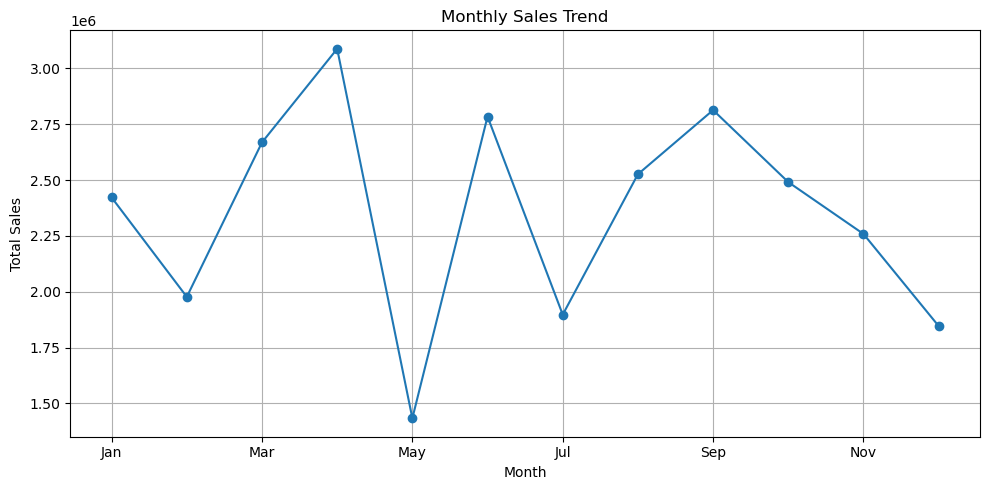

In [18]:
monthly_sales = (
    df.groupby("Month")["Sales"].sum()
    .reindex([
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ])
)

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

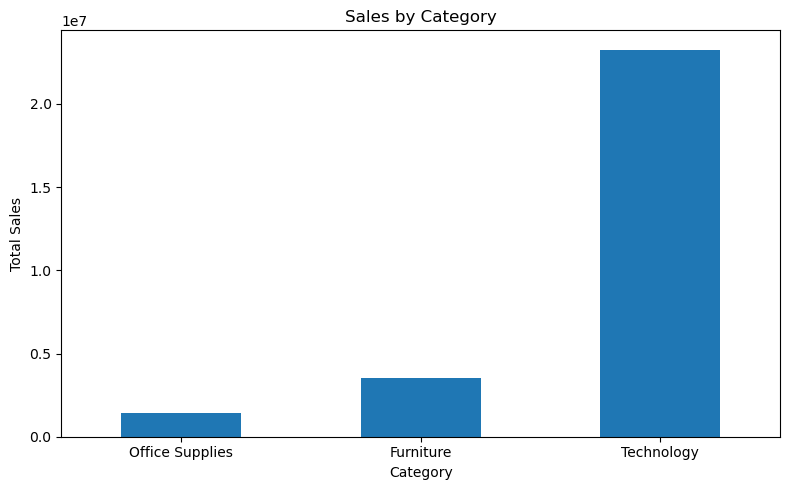

In [19]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values()

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

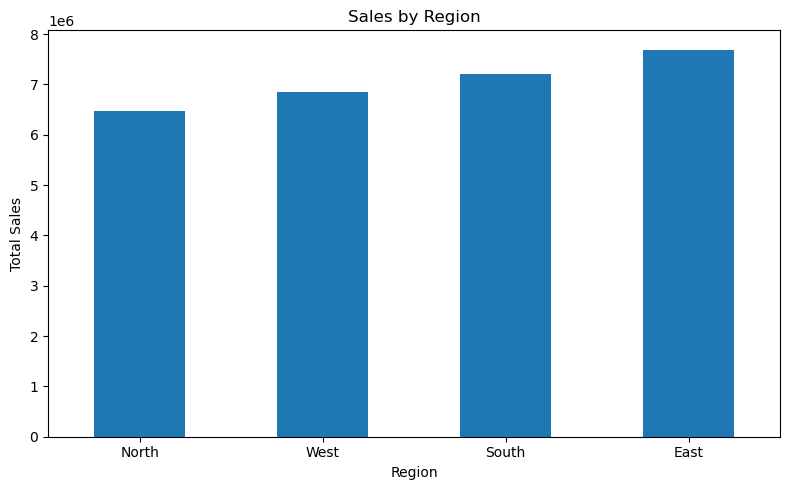

In [20]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values()

region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

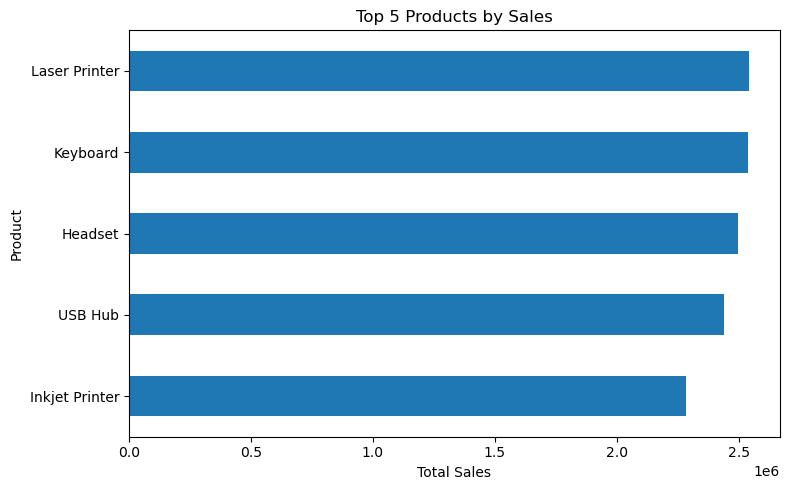

In [21]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .nlargest(5)
    .sort_values()
)

top_products.plot(kind="barh", figsize=(8, 5))
plt.title("Top 5 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [22]:
# 1. Overall KPIs
print("OVERALL BUSINESS PERFORMANCE:")
print(f"Total Sales: {df['Sales'].sum():,.2f}")
print(f"Total Profit: {df['Profit'].sum():,.2f}")
print(f"Total Quantity: {df['Quantity'].sum():,}")

# 2. Category performance
print("\nSALES BY CATEGORY:")
print(
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
    .round(2)
)

# 3. Regional performance
print("\nSALES BY REGION:")
print(
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
    .round(2)
)

# 4. Top 5 products
print("\nTOP 5 PRODUCTS:")
print(
    df.groupby("Product Name")["Sales"]
    .sum()
    .nlargest(5)
    .round(2)
)

OVERALL BUSINESS PERFORMANCE:
Total Sales: 28,206,799.62
Total Profit: 3,669,196.05
Total Quantity: 2,013

SALES BY CATEGORY:
                       Sales      Profit
Category                                
Technology       23257553.49  3044292.89
Furniture         3535383.63   445930.20
Office Supplies   1413862.50   178972.96

SALES BY REGION:
             Sales      Profit
Region                        
East    7688556.73  1000696.54
South   7211184.30  1007683.67
West    6840045.40   864726.85
North   6467013.19   796088.99

TOP 5 PRODUCTS:
Product Name
Laser Printer     2541920.17
Keyboard          2538982.23
Headset           2498101.25
USB Hub           2437685.72
Inkjet Printer    2283390.41
Name: Sales, dtype: float64


In [23]:
df.to_csv("Retail_Sales_Cleaned_Python.csv", index=False)

In [24]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity:", df["Quantity"].sum())
print("Total Records:", len(df))

Total Sales: 28206799.62
Total Profit: 3669196.05
Total Quantity: 2013
Total Records: 500


In [25]:
df.to_csv("Retail_Sales_Cleaned_Final.csv", index=False)

print("Final cleaned CSV saved successfully.")

Final cleaned CSV saved successfully.


In [27]:
print("Rows in Python:", len(df))
print(df[["Sales", "Profit", "Quantity"]].head())

Rows in Python: 500
       Sales    Profit  Quantity
0   14565.72   2664.67         6
1  153118.95  29734.03         5
2   14739.16   2479.43         4
3   87786.90   5093.42         2
4    8985.34   2072.17         1


In [28]:
df.to_csv(
    "Retail_Sales_Cleaned_Final.csv",
    index=False,
    encoding="utf-8"
)

print("CSV exported:", len(df), "rows")

CSV exported: 500 rows
